# ACE mouse tiny example

This notebook runs ACE on a small real mouse droplet single-cell dataset sampled from the Tabula Muris Senis / CZ CELLxGENE workflow used in the manuscript. It is intended as a reproducible example for the public repository, not as a full benchmark.

The notebook calls the command-line workflow in `examples/mouse_aging_workflow.py`, then displays the age-prediction and representation-quality metrics.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd

repo_root = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
if not (repo_root / "examples" / "mouse_aging_workflow.py").exists():
    raise RuntimeError("Run this notebook from the ACE repository root or notebook/ directory.")

adata_rel = Path("data") / "ace_mouse_tiny.h5ad"
out_rel = Path("results") / "mouse_tiny_notebook"
adata_path = repo_root / adata_rel
out_dir = repo_root / out_rel
print("dataset:", adata_rel)
print("output:", out_rel)

dataset: data/ace_mouse_tiny.h5ad
output: results/mouse_tiny_notebook


## Run ACE

This reviewer example trains for `--max-epochs 100`, which is long enough for the small real mouse subset to show an age-ordered salient latent space while still running quickly on CPU. Increase `--max-epochs` for manuscript-scale analyses.


In [2]:
cmd = [
    sys.executable, str(Path("examples") / "mouse_aging_workflow.py"),
    "--adata", str(adata_rel),
    "--output-dir", str(out_rel),
    "--max-epochs", "100",
    "--n-salient-latent", "3",
    "--n-background-latent", "5",
    "--metric-pairs", "1000",
    "--save-all-latent",
]
print("python " + " ".join(cmd[1:]))
completed = subprocess.run(cmd, cwd=repo_root, text=True, capture_output=True)
if completed.returncode != 0:
    print(completed.stdout)
    print(completed.stderr)
    completed.check_returncode()
for line in completed.stdout.splitlines():
    if line.startswith("Wrote outputs"):
        print(line)

python examples/mouse_aging_workflow.py --adata data/ace_mouse_tiny.h5ad --output-dir results/mouse_tiny_notebook --max-epochs 100 --n-salient-latent 3 --n-background-latent 5 --metric-pairs 1000 --save-all-latent
Wrote outputs to results/mouse_tiny_notebook


## Outputs

In [3]:
sorted(p.name for p in out_dir.iterdir())

['ace_model',
 'age_prediction_metrics.csv',
 'background_latent.csv',
 'background_latent.h5ad',
 'background_latent_all.h5ad',
 'salient_latent.csv',
 'salient_latent.h5ad',
 'salient_latent_all.h5ad',
 'salient_metrics_age_corr.csv']

## Latent space visualization

As in the mouse droplet workflow, the latent spaces are visualized with PC and UMAP plots. For this compact example, UMAPs are shown for all cells to provide enough points to inspect the age pattern; held-out cells are still used for the quantitative age-prediction and representation metrics below.


In [4]:
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
import warnings

warnings.filterwarnings("ignore", message="No data for colormapping provided via.*")
sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=90, facecolor="white", frameon=False)
plot_keys = ["age_float", "cell_type", "tissue", "sex"]

def prepare_latent_embedding(path, n_neighbors=15):
    embedding = ad.read_h5ad(path)
    n_comps = min(2, embedding.n_vars, embedding.n_obs - 1)
    sc.pp.pca(embedding, n_comps=n_comps, random_state=0)
    sc.pp.neighbors(
        embedding,
        n_neighbors=min(n_neighbors, embedding.n_obs - 1),
        use_rep="X",
    )
    sc.tl.umap(embedding, random_state=0)
    return embedding

salient_embed = prepare_latent_embedding(out_dir / "salient_latent_all.h5ad")
background_embed = prepare_latent_embedding(out_dir / "background_latent_all.h5ad")

2026-10-11 00:19:58.744031: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 00:19:58.766149: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-11 00:19:58.785181: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-11 00:19:58.791256: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-11 00:19:58.804717: I tensorflow/core/platform/cpu_feature_guar

### Salient latent space

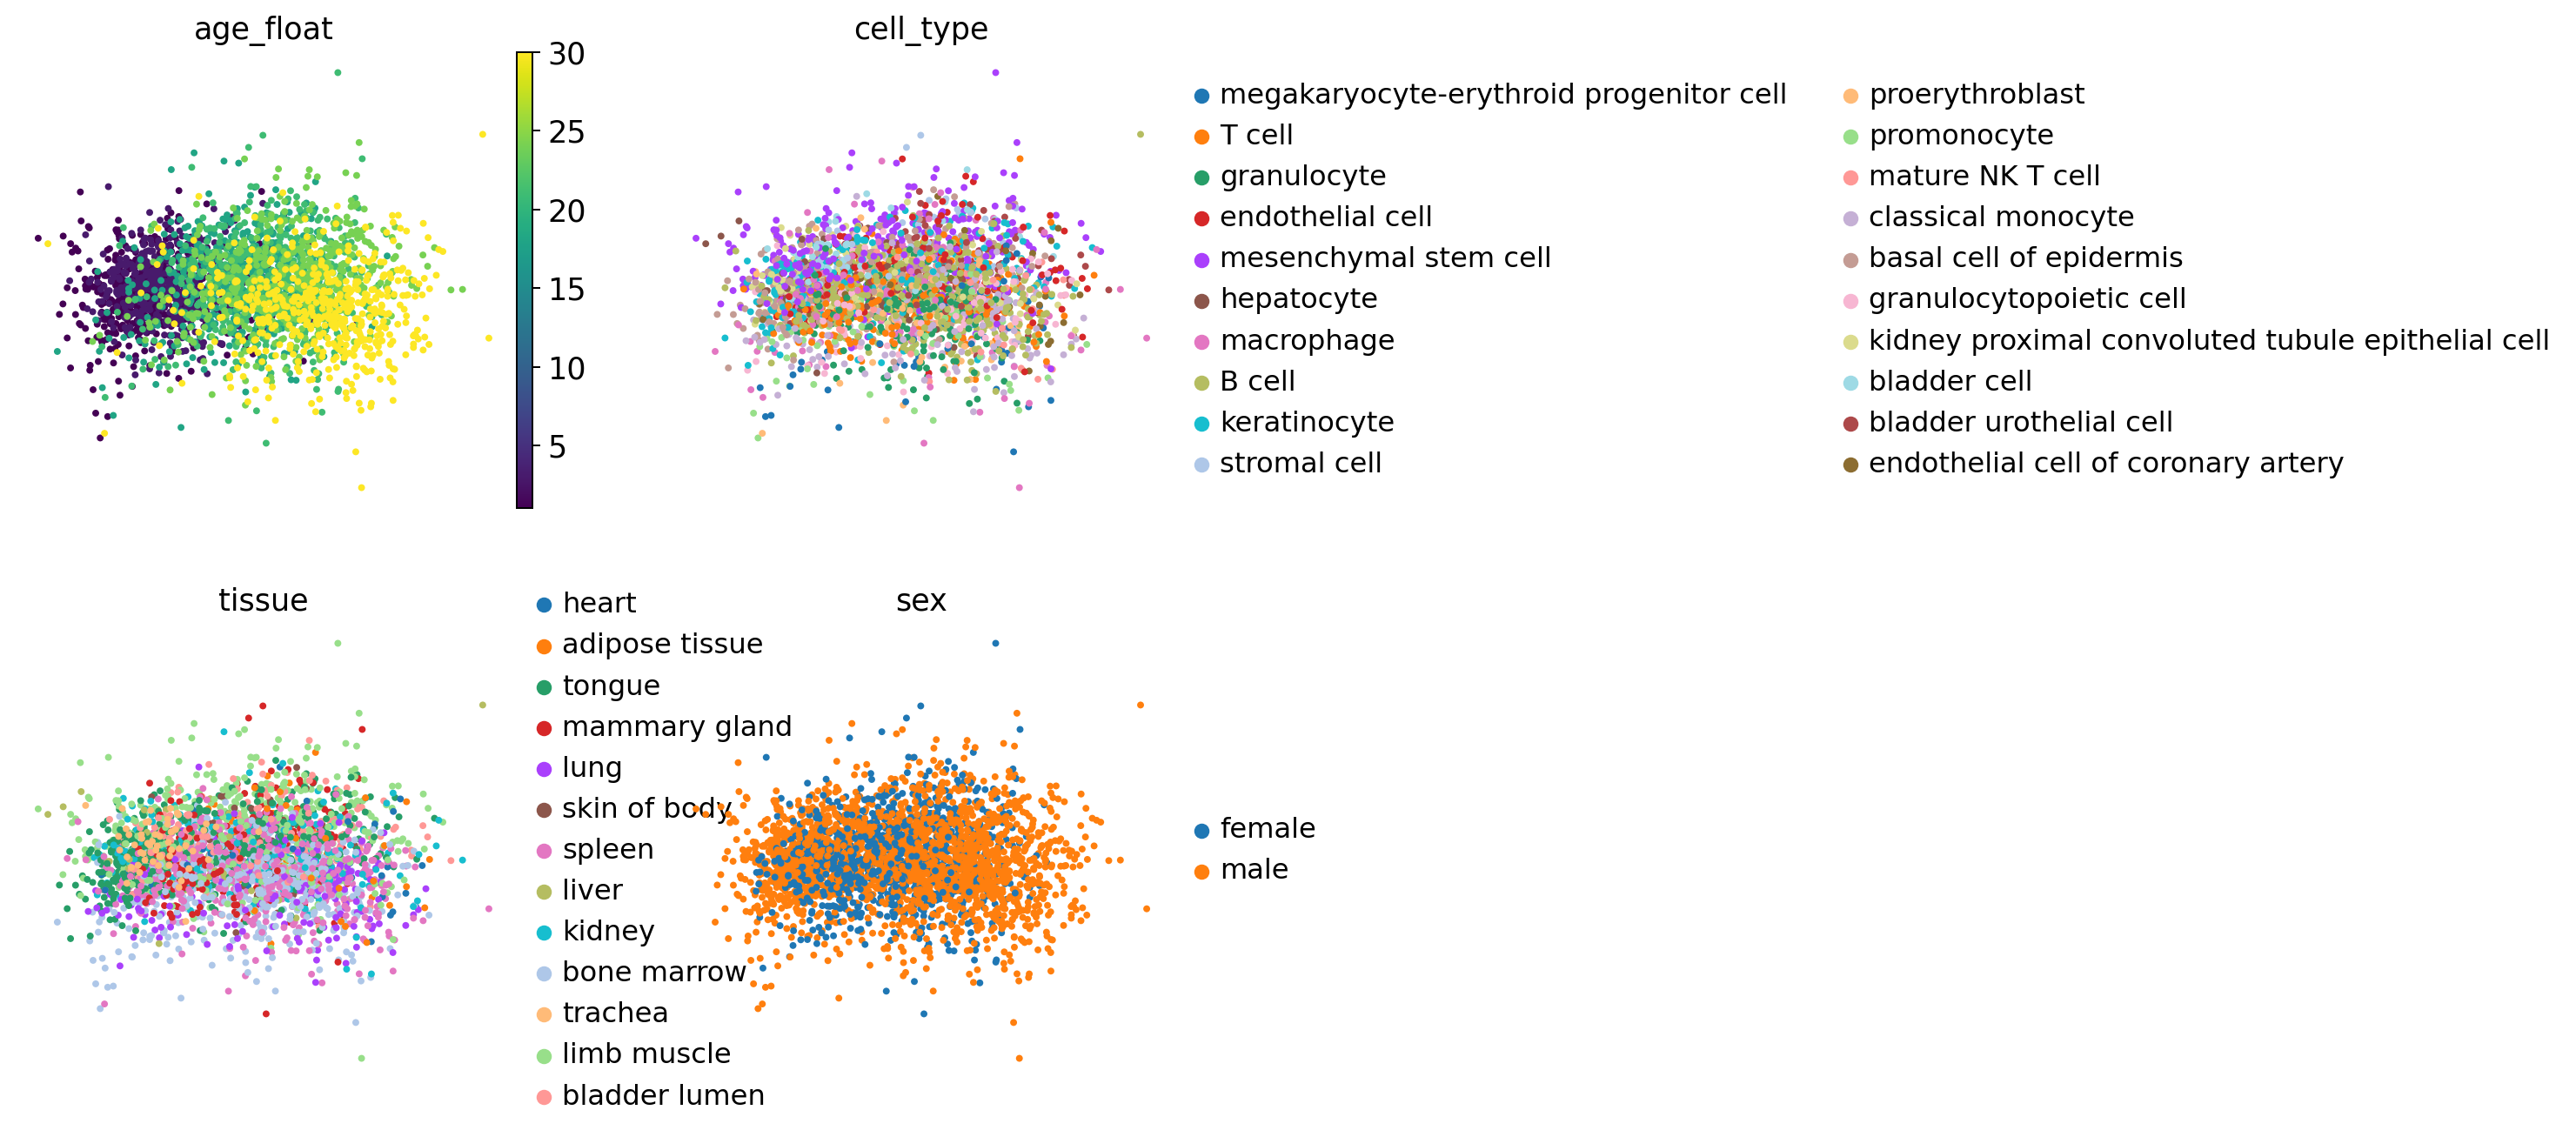

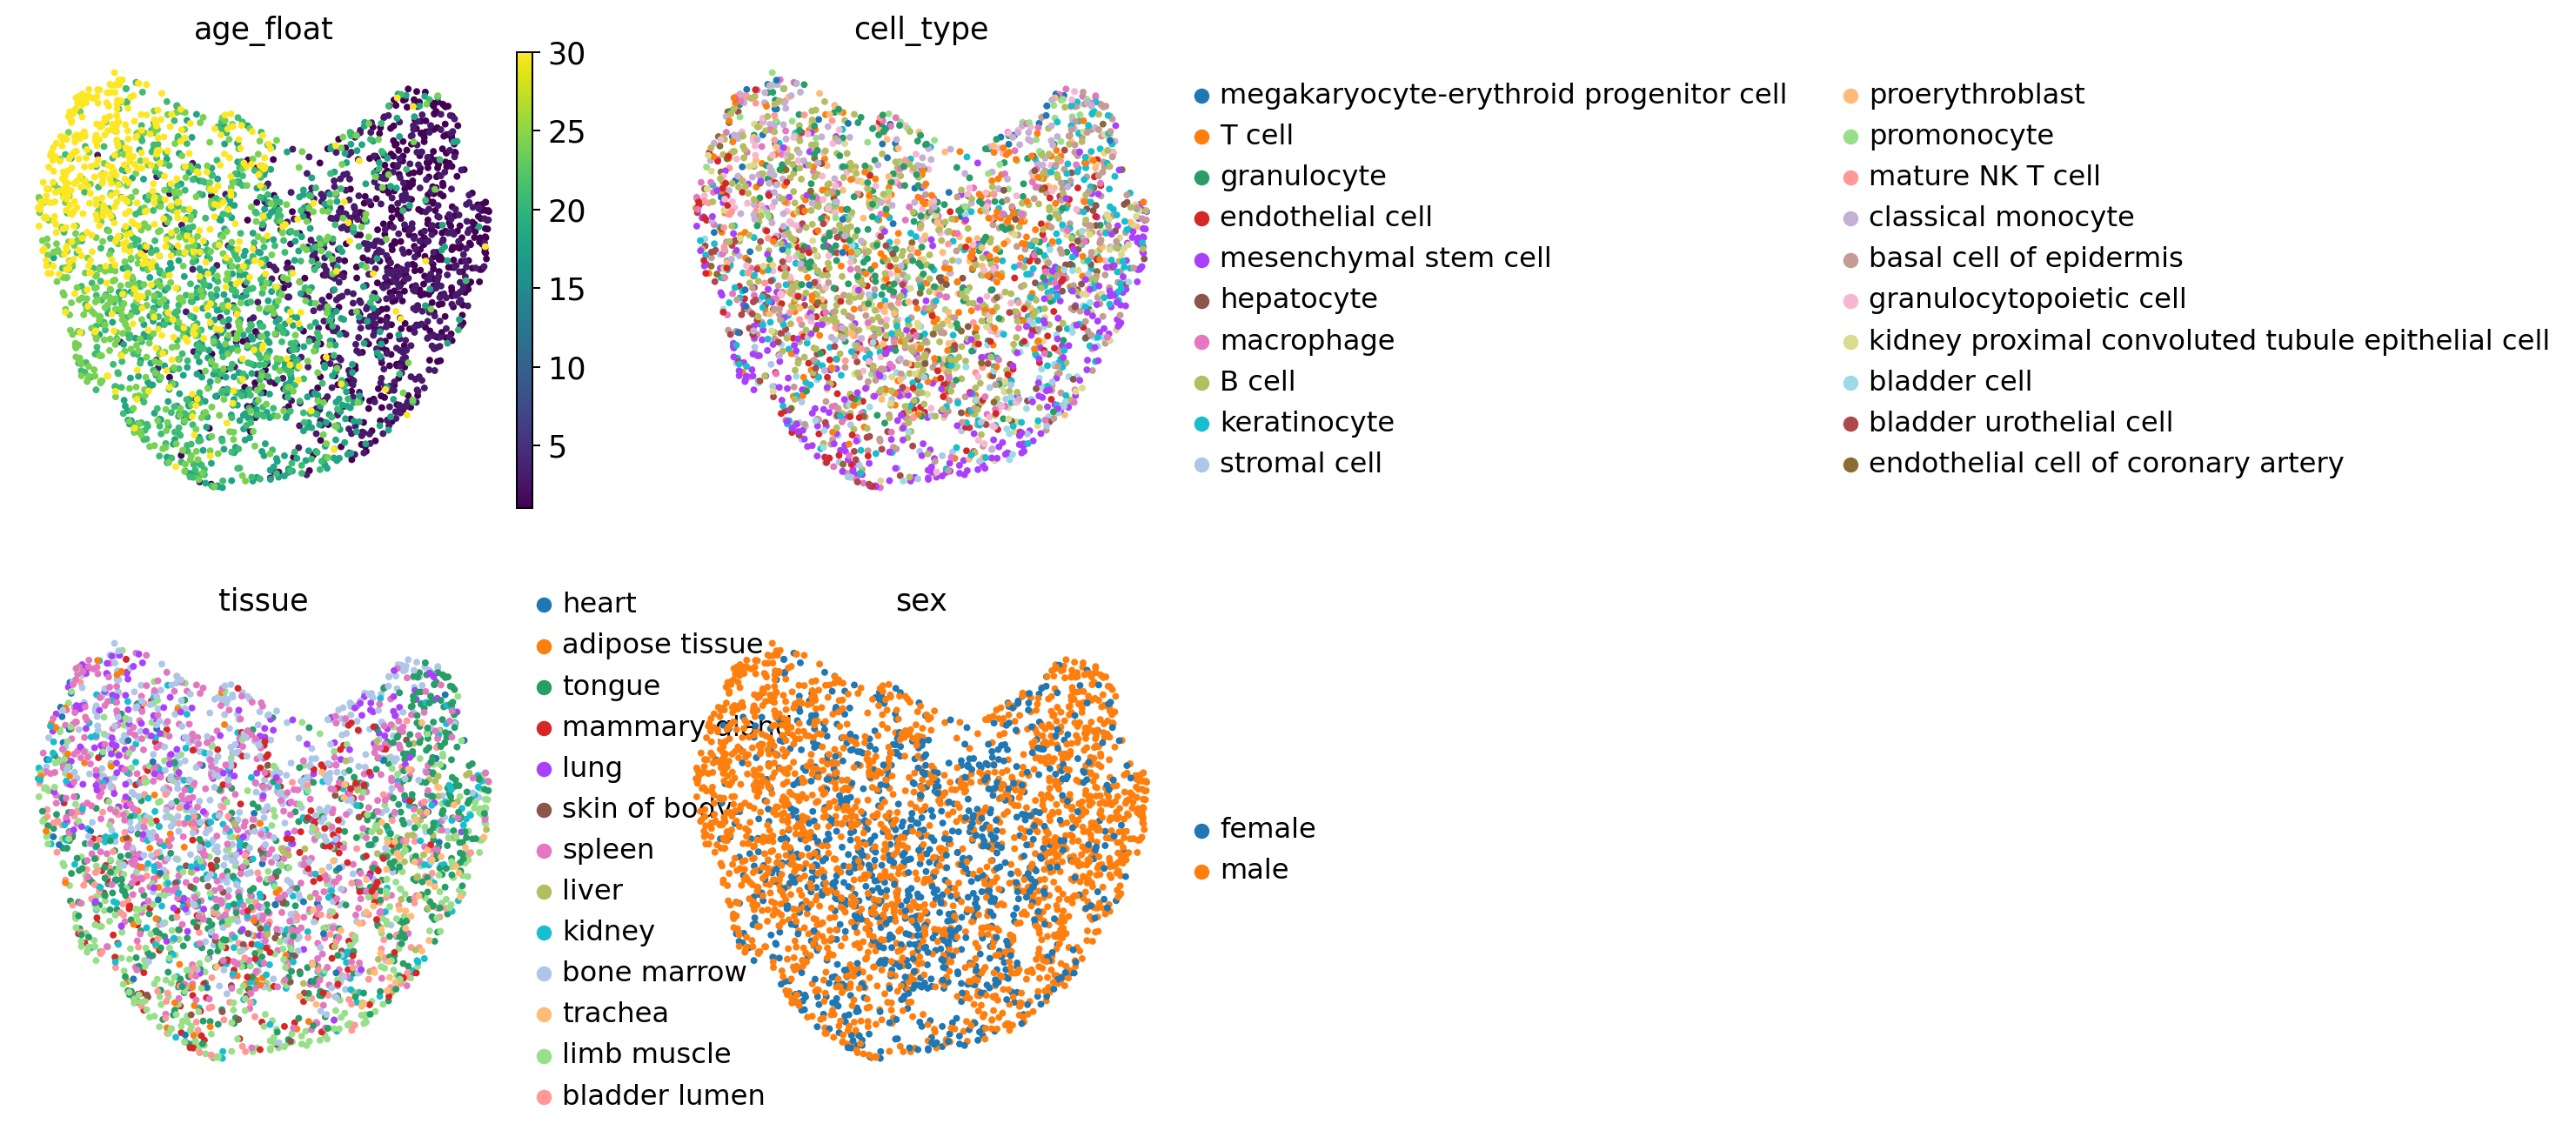

In [5]:
sc.pl.pca(salient_embed, color=plot_keys, ncols=2, frameon=False, show=True)
sc.pl.umap(salient_embed, color=plot_keys, ncols=2, frameon=False, show=True)

### Background latent space

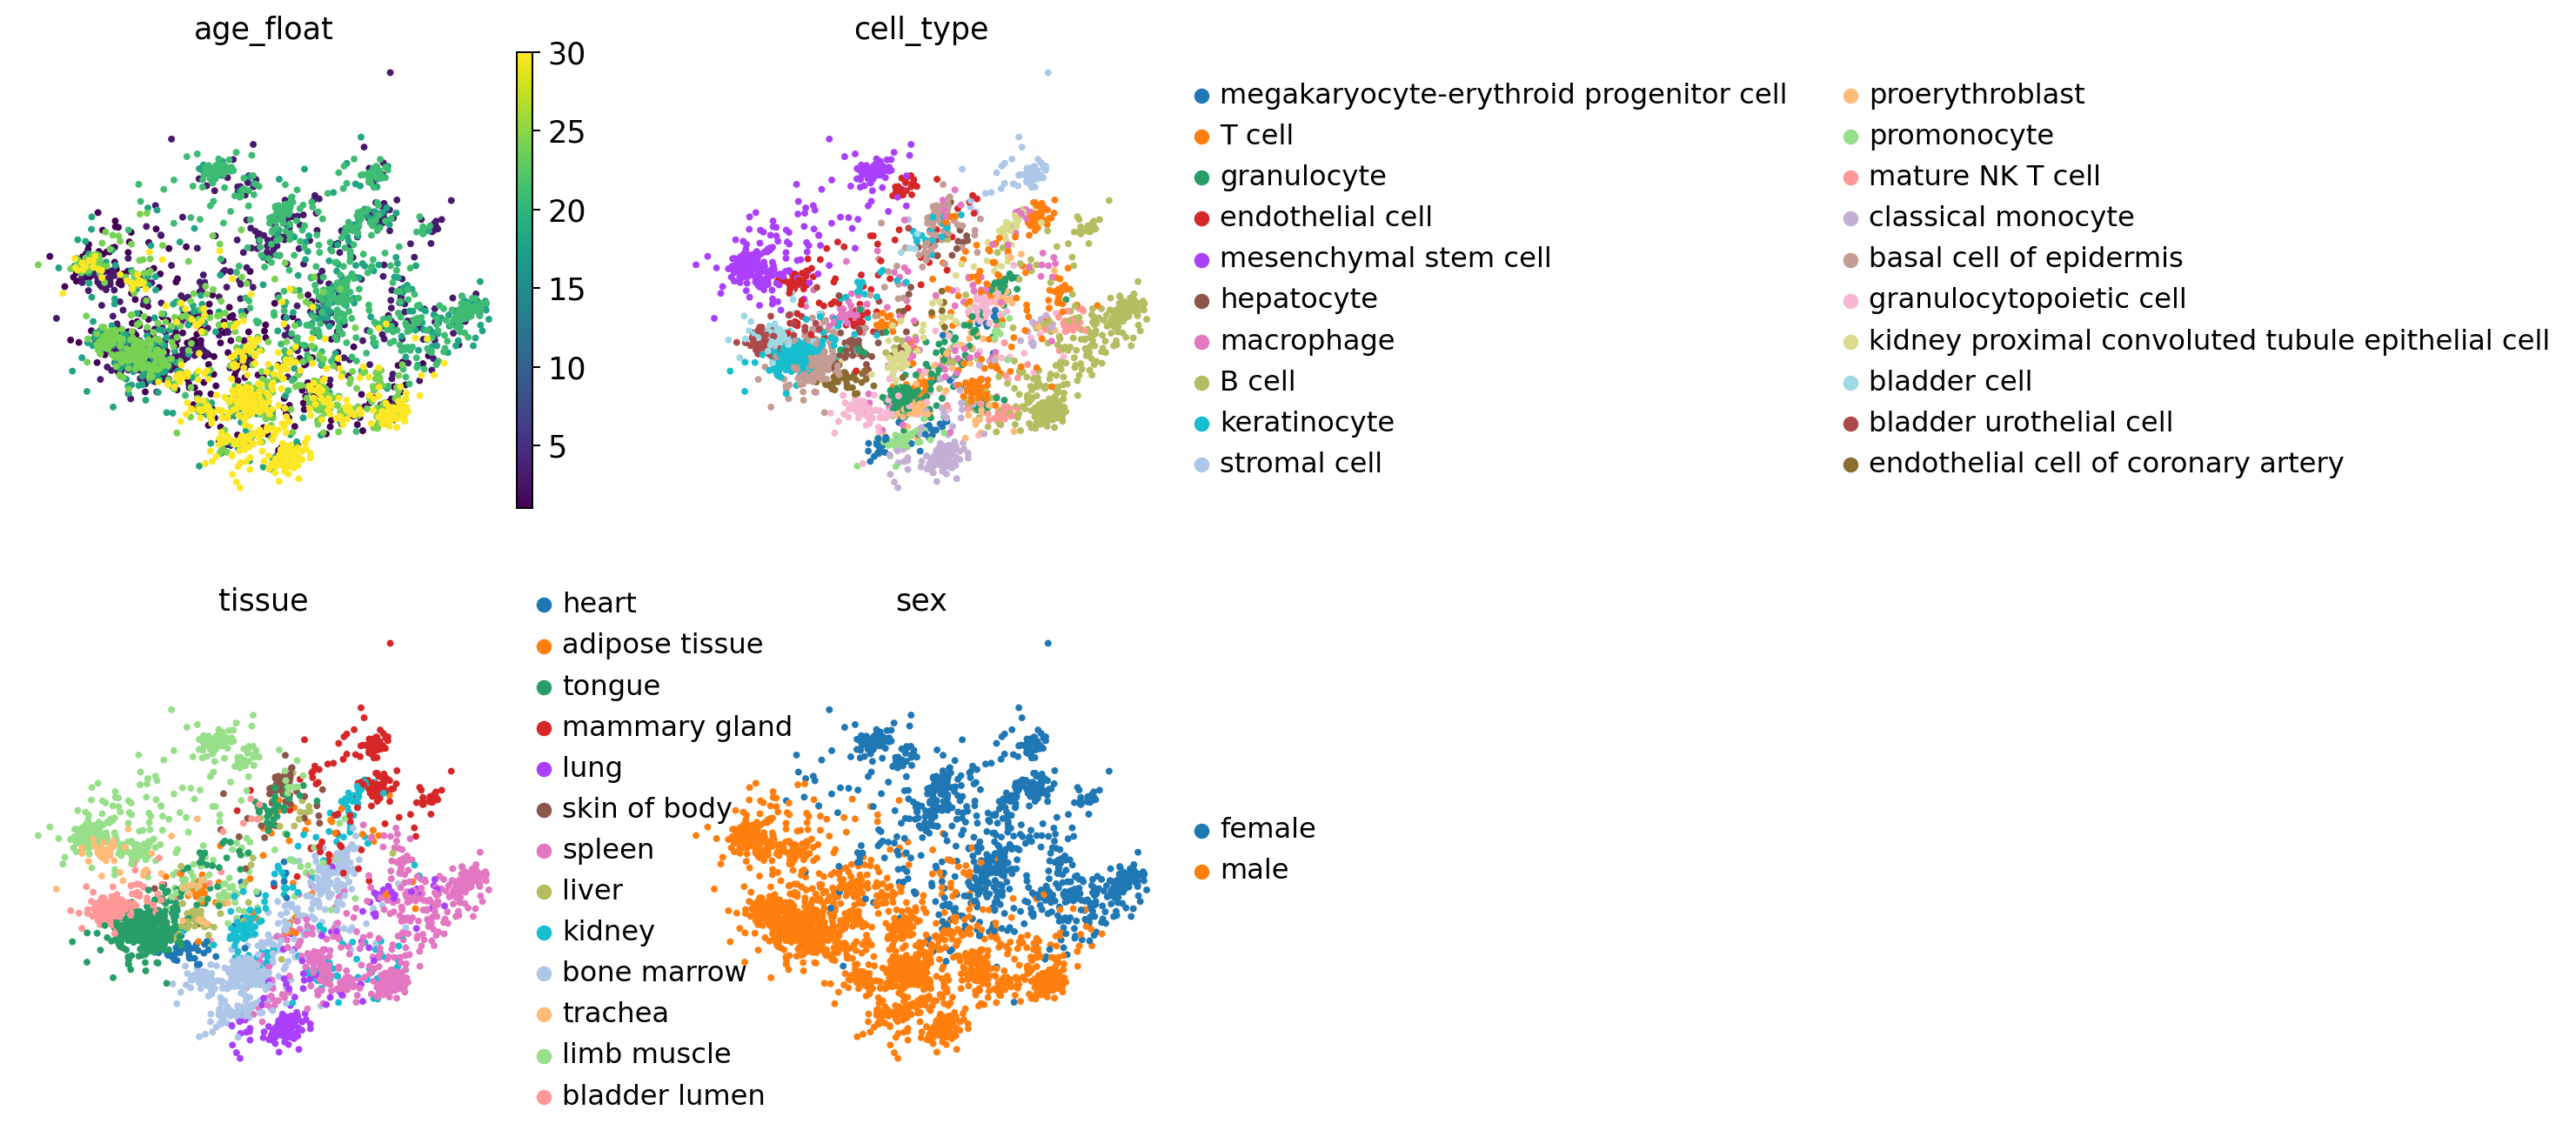

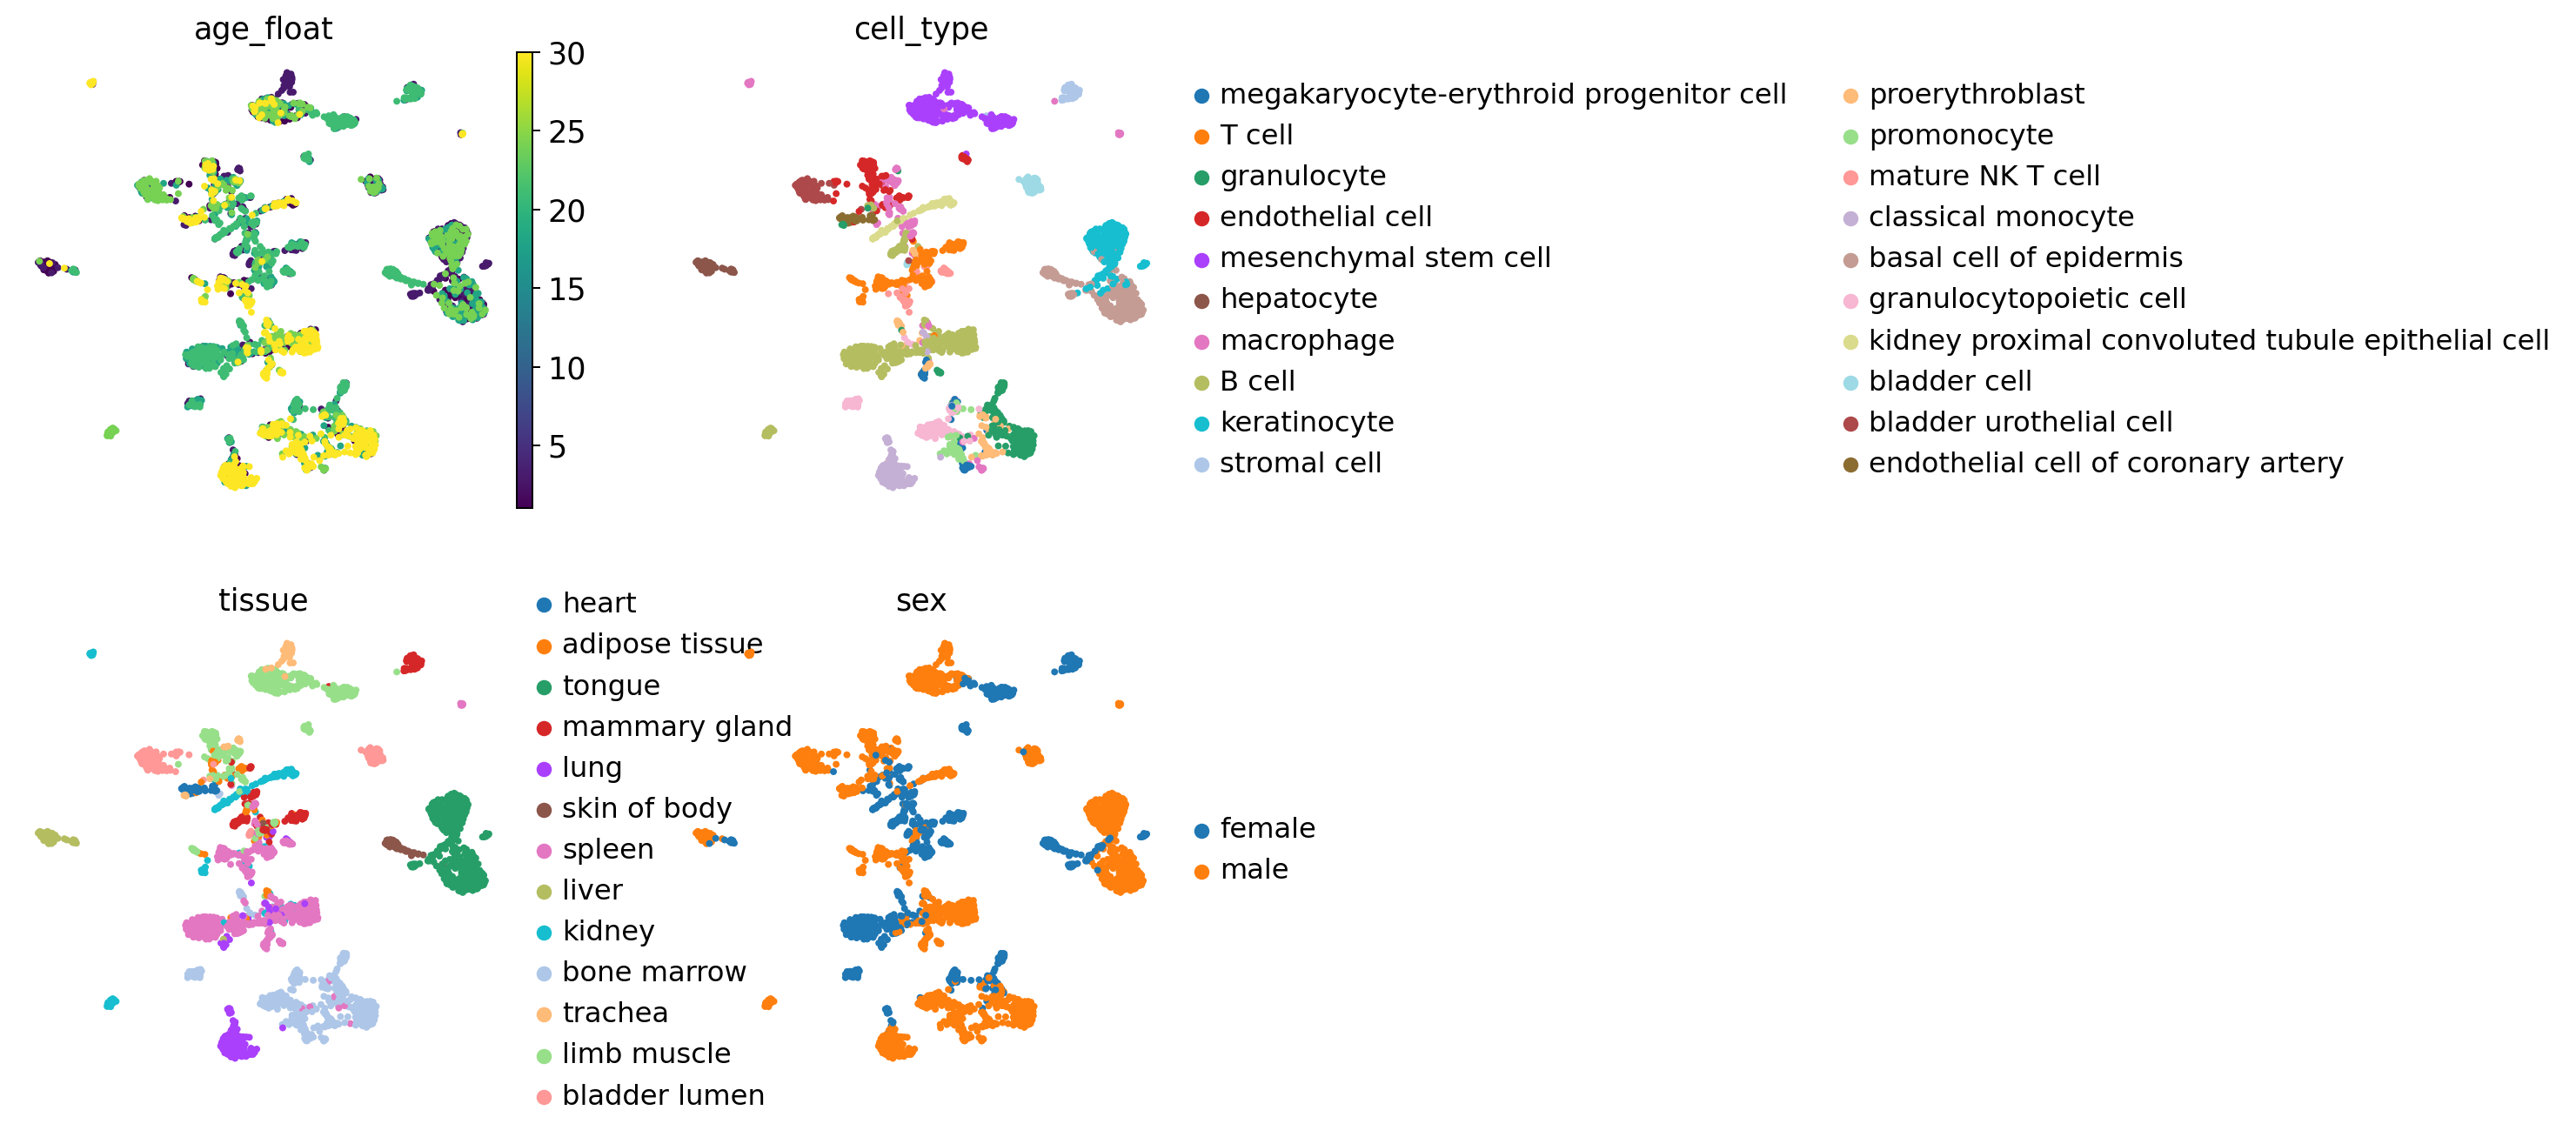

In [6]:
sc.pl.pca(background_embed, color=plot_keys, ncols=2, frameon=False, show=True)
sc.pl.umap(background_embed, color=plot_keys, ncols=2, frameon=False, show=True)

A ridge regressor is fit on the training salient embedding and evaluated on held-out cells. This compact reviewer run is intended to demonstrate the workflow rather than reproduce the full manuscript benchmark.


In [7]:
age_metrics = pd.read_csv(out_dir / "age_prediction_metrics.csv")
age_metrics

,n_train,n_test,r2,rmse,ridge_alpha
0,2400,600,0.302036,8.445779,0.316228


## Representation metrics

These metrics are adapted from the manuscript mouse droplet evaluation. Higher age-correlation metrics indicate stronger age ordering in the salient latent space; entropy mixing metrics summarize mixing of cell traits in the salient space.

In [8]:
salient_metrics = pd.read_csv(out_dir / "salient_metrics_age_corr.csv", index_col=0)
salient_metrics

,value
gearys_c,6.569721e-01
morans_i,3.451673e-01
distance_age_n_pairs,1.000000e+03
distance_age_spearman_r,2.139823e-01
distance_age_spearman_p,8.053038e-12
distance_age_pearson_r,2.414038e-01
distance_age_pearson_p,1.001646e-14
age_bin_centroid_monotonicity_spearman_r,9.749568e-01
geodesic_distance_age_spearman_r,2.213773e-01
adjacent_age_connectivity_ratio,4.535470e-01


In [9]:
selected_metrics = salient_metrics.loc[[
    "morans_i",
    "distance_age_spearman_r",
    "geodesic_distance_age_spearman_r",
    "cell_type_AllAge_entropy_batch_mixing",
    "tissue_AllAge_entropy_batch_mixing",
    "sex_AllAge_entropy_batch_mixing",
]]
selected_metrics

,value
morans_i,0.345167
distance_age_spearman_r,0.213982
geodesic_distance_age_spearman_r,0.221377
cell_type_AllAge_entropy_batch_mixing,2.211015
tissue_AllAge_entropy_batch_mixing,1.879029
sex_AllAge_entropy_batch_mixing,0.627946
